# research questions



## <Descriptive>
### Which periods of revenue / timings are the most lucrative?
### Aggregate based on revenue - organize by VisitorType?
### How do new and returning visitors differ in purchase rate and browsing behavior?

## <relationship/correlation>
### Are people who spend more time browsing products more likely to purchase?
##  Purchase = a + b1(time) + err


##############

  Are lower bounce rates and exit rates associated with a higher likelihood of purchase?
############# Purchase = a + b1(bounce_rate) + b2(exit_rate) + err
############# What are the most important factors/variables that predict/explain when an online shopper makes a purchase?
############# ## Purchase = a + b1(??) + b2(??) + b3 ..... + err




# 01. EDA.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/online_shoppers_intention.csv')
df.shape

(12330, 18)

In [2]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
df['Month'].value_counts()

Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64

In [4]:
df


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False


BounceRates - Average bounce rate value of the pages visited by the visitor. sing page visit or unengaed session / total visits single page session 'did they leave right after arriving?, inversse of engagemetn rate. bounce rate = 100 - engagement rate. So lower bounce rate is better? it means stayed longer?

ExitRates - Average exit rate value of the pages visited by the visitor.  number of exits from a page / total pageviews for that page (final), where did they finally leave the site?

PageValues - Average page value of the pages visited by the visitor

Revenue - Class label indicating whether the visit has been finalized with a transaction

ProductRelated - Number of pages visited by visitor about product related pages 

ProductRelated_Duration - Total amount of time (in seconds) spent by the visitor on product related pages 

VisitorType - Visitor type as ‘‘NewVisitor,’’ ‘‘ReturningVisitor,’’and ‘‘Other’’ 

Weekend
Month
SpecialDay - Closeness of the site visiting time to a special day



In [5]:
df['Revenue'].dtype

dtype('bool')

In [6]:
df.dtypes
# weekend? Muslim holidays?



Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object

In [7]:
df.isna().sum()
df.isnull().sum()
# 0 missing variable?

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

## individual variable level

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


In [9]:
df['Region'].value_counts()

Region
1    4780
3    2403
4    1182
2    1136
6     805
7     761
9     511
8     434
5     318
Name: count, dtype: int64

In [10]:
df.Month.value_counts()

# this tells us dataset is from one year. 

Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64

In [11]:
# creating numeric value for the Month.
df

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False


In [12]:
df['VisitorType'].value_counts()
# 3 visitor types, not sure what other means. 

VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64

In [13]:
clean_df = df[df["VisitorType"] != "Other"]



In [14]:
clean_df.duplicated().sum()

np.int64(121)

In [15]:
clean_df.duplicated().sum()

np.int64(121)

In [16]:
clean_df = clean_df.drop_duplicates()

In [17]:
clean_df.describe().T # outliers?
# Administrative_Duration, Informational_Duration, Informational_Duration, BounceRates, ExitRates, PageValues






,count,mean,std,min,25%,50%,75%,max
Administrative,12124.0,2.344193,3.334480,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12124.0,81.752255,177.272187,0.0,0.000000,9.333333,95.000000,3398.750000
Informational,12124.0,0.510887,1.278299,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12124.0,34.976196,141.797257,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12124.0,32.172633,44.662864,0.0,8.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12124.0,1211.047219,1922.508742,0.0,195.625000,613.944583,1483.341666,63973.522230
BounceRates,12124.0,0.020302,0.045027,0.0,0.000000,0.002995,0.016667,0.200000
ExitRates,12124.0,0.041364,0.045990,0.0,0.014264,0.025000,0.048238,0.200000
PageValues,12124.0,5.861782,18.156144,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12124.0,0.062356,0.200268,0.0,0.000000,0.000000,0.000000,1.000000


In [18]:
results = []

columns = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration","PageValues"
]
# "BounceRates", "ExitRates". Main variables not included in the first outliers list as the median VS mean checking shows us. We may need to check this later.
# For now, only the extreme ones are exluded

# Start with a copy of the original dataframe
final_df = clean_df.copy()

# Apply IQR method to each column
for col in columns:
    Q1 = final_df[col].quantile(0.10)
    Q3 = final_df[col].quantile(0.90)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Remove rows containing outliers
    final_df = final_df[
        (final_df[col] >= lower_bound) &
        (final_df[col] <= upper_bound)
    ]

final_df.describe().T




,count,mean,std,min,25%,50%,75%,max
Administrative,10398.0,1.852664,2.733318,0.0,0.000000,0.000000,3.000000,17.000000
Administrative_Duration,10398.0,52.567130,91.132187,0.0,0.000000,0.000000,71.325000,559.166667
Informational,10398.0,0.253510,0.708007,0.0,0.000000,0.000000,0.000000,5.000000
Informational_Duration,10398.0,6.056548,20.377809,0.0,0.000000,0.000000,0.000000,136.000000
ProductRelated,10398.0,24.466436,25.915095,0.0,7.000000,16.000000,32.000000,158.000000
ProductRelated_Duration,10398.0,875.047827,1020.755795,0.0,158.943333,502.983333,1218.082738,5793.523810
BounceRates,10398.0,0.022699,0.048055,0.0,0.000000,0.003125,0.019048,0.200000
ExitRates,10398.0,0.045039,0.048384,0.0,0.015164,0.028000,0.051150,0.200000
PageValues,10398.0,2.604118,7.572457,0.0,0.000000,0.000000,0.000000,44.443614
SpecialDay,10398.0,0.067878,0.208276,0.0,0.000000,0.000000,0.000000,1.000000


In [19]:
final_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,10398.0,1.852664,2.733318,0.0,0.000000,0.000000,3.000000,17.000000
Administrative_Duration,10398.0,52.567130,91.132187,0.0,0.000000,0.000000,71.325000,559.166667
Informational,10398.0,0.253510,0.708007,0.0,0.000000,0.000000,0.000000,5.000000
Informational_Duration,10398.0,6.056548,20.377809,0.0,0.000000,0.000000,0.000000,136.000000
ProductRelated,10398.0,24.466436,25.915095,0.0,7.000000,16.000000,32.000000,158.000000
ProductRelated_Duration,10398.0,875.047827,1020.755795,0.0,158.943333,502.983333,1218.082738,5793.523810
BounceRates,10398.0,0.022699,0.048055,0.0,0.000000,0.003125,0.019048,0.200000
ExitRates,10398.0,0.045039,0.048384,0.0,0.015164,0.028000,0.051150,0.200000
PageValues,10398.0,2.604118,7.572457,0.0,0.000000,0.000000,0.000000,44.443614
SpecialDay,10398.0,0.067878,0.208276,0.0,0.000000,0.000000,0.000000,1.000000


In [20]:
# creating a minute variable

final_df['ProductRelated_Duration_minutes'] = final_df['ProductRelated_Duration'] / 60



In [21]:
final_df["converted_revenue"] = final_df["Revenue"].astype(int)          # 1 = purchase, 0 = no purchase

In [22]:
## Which periods of revenue / timings are the most lucrative?

lucrative_period = (final_df.groupby("Month")["converted_revenue"].agg(sessions="count", purchases="sum", purchase_per_sessions = "mean")).sort_values(by='sessions', ascending= False).reset_index()
lucrative_period


,Month,sessions,purchases,purchase_per_sessions
0,May,2958,228,0.077079
1,Nov,2370,449,0.189451
2,Mar,1659,110,0.066305
3,Dec,1418,127,0.089563
4,Oct,446,70,0.156951
5,Jul,377,48,0.127321
6,Sep,374,62,0.165775
7,Aug,365,52,0.142466
8,June,253,23,0.090909
9,Feb,178,2,0.011236


In [23]:
lucrative_period['Month_n'] = pd.to_datetime(lucrative_period['Month']).dt.month
lucrative_period

/var/folders/8v/v2c4n_w51456g3mxc_p0cd200000gn/T/ipykernel_46415/4206670198.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  lucrative_period['Month_n'] = pd.to_datetime(lucrative_period['Month']).dt.month


,Month,sessions,purchases,purchase_per_sessions,Month_n
0,May,2958,228,0.077079,5
1,Nov,2370,449,0.189451,11
2,Mar,1659,110,0.066305,3
3,Dec,1418,127,0.089563,12
4,Oct,446,70,0.156951,10
5,Jul,377,48,0.127321,7
6,Sep,374,62,0.165775,9
7,Aug,365,52,0.142466,8
8,June,253,23,0.090909,6
9,Feb,178,2,0.011236,2


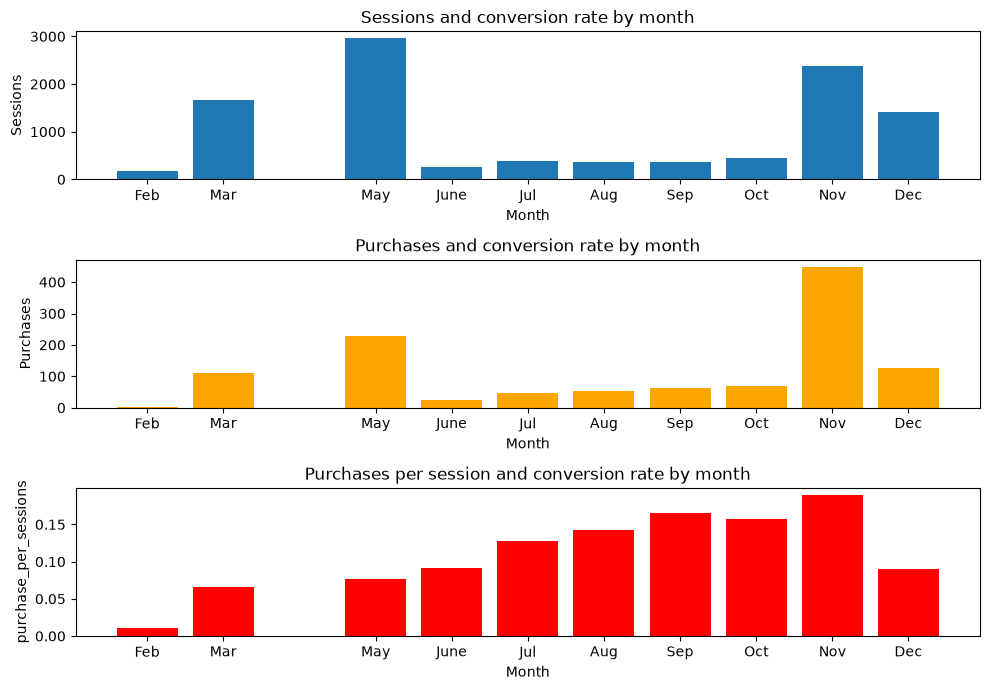

In [24]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

ax1.bar(lucrative_period['Month_n'], lucrative_period['sessions'])
ax1.set_ylabel('Sessions')
ax1.set_title('Sessions and conversion rate by month')

ax2.bar(lucrative_period['Month_n'], lucrative_period['purchases'], color='orange')
ax2.set_ylabel('Purchases')
ax2.set_title('Purchases and conversion rate by month')

ax3.bar(lucrative_period['Month_n'], lucrative_period['purchase_per_sessions'], color='red')
ax3.set_ylabel('purchase_per_sessions')
ax3.set_title('Purchases per session and conversion rate by month')

for ax in (ax1, ax2, ax3):
    ax.set_xticks(lucrative_period['Month_n'])                          # a tick at every month
    ax.set_xticklabels(lucrative_period['Month'])                        # name each tick
    ax.tick_params(labelbottom=True)     # show labels even on shared axes
    ax.set_xlabel('Month')

plt.tight_layout()
plt.show()



In [25]:
# May and November are the most visited month. The most purchases were made in November and May is next. Purhcases per session rate is very interesting. November still has the highest purhcases per sessions but not that higher than other months. May has considerably lower purhcase per session regardless of second high purchases.
# this means lots of visitors in May, but they didn't actually buy that much..
# now let's look into other variables, like time.

In [26]:
lucrative_period_deep = (final_df.groupby("Month")[['converted_revenue', 'ProductRelated_Duration_minutes', 'BounceRates', 'ExitRates']].agg(sessions=('converted_revenue', 'count'),
            purchases=('converted_revenue', 'sum'),
            purchase_rate=('converted_revenue', 'mean'),
            browse_time=('ProductRelated_Duration_minutes', 'mean'),
            avg_bounce_rate=('BounceRates', 'mean'),
            avg_exit_rates=('ExitRates', 'mean')).reset_index()
)
lucrative_period_deep

,Month,sessions,purchases,purchase_rate,browse_time,avg_bounce_rate,avg_exit_rates
0,Aug,365,52,0.142466,15.722564,0.020219,0.041144
1,Dec,1418,127,0.089563,14.188723,0.020046,0.042207
2,Feb,178,2,0.011236,7.118037,0.044955,0.072826
3,Jul,377,48,0.127321,14.295361,0.026875,0.048235
4,June,253,23,0.090909,12.558263,0.036675,0.061055
5,Mar,1659,110,0.066305,11.358791,0.018778,0.043482
6,May,2958,228,0.077079,13.548917,0.027418,0.050711
7,Nov,2370,449,0.189451,19.189226,0.020944,0.041497
8,Oct,446,70,0.156951,13.667211,0.013152,0.031612
9,Sep,374,62,0.165775,14.593227,0.013487,0.032788


In [27]:
lucrative_period_deep['Month_n'] = pd.to_datetime(lucrative_period_deep['Month']).dt.month


/var/folders/8v/v2c4n_w51456g3mxc_p0cd200000gn/T/ipykernel_46415/1101243636.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  lucrative_period_deep['Month_n'] = pd.to_datetime(lucrative_period_deep['Month']).dt.month


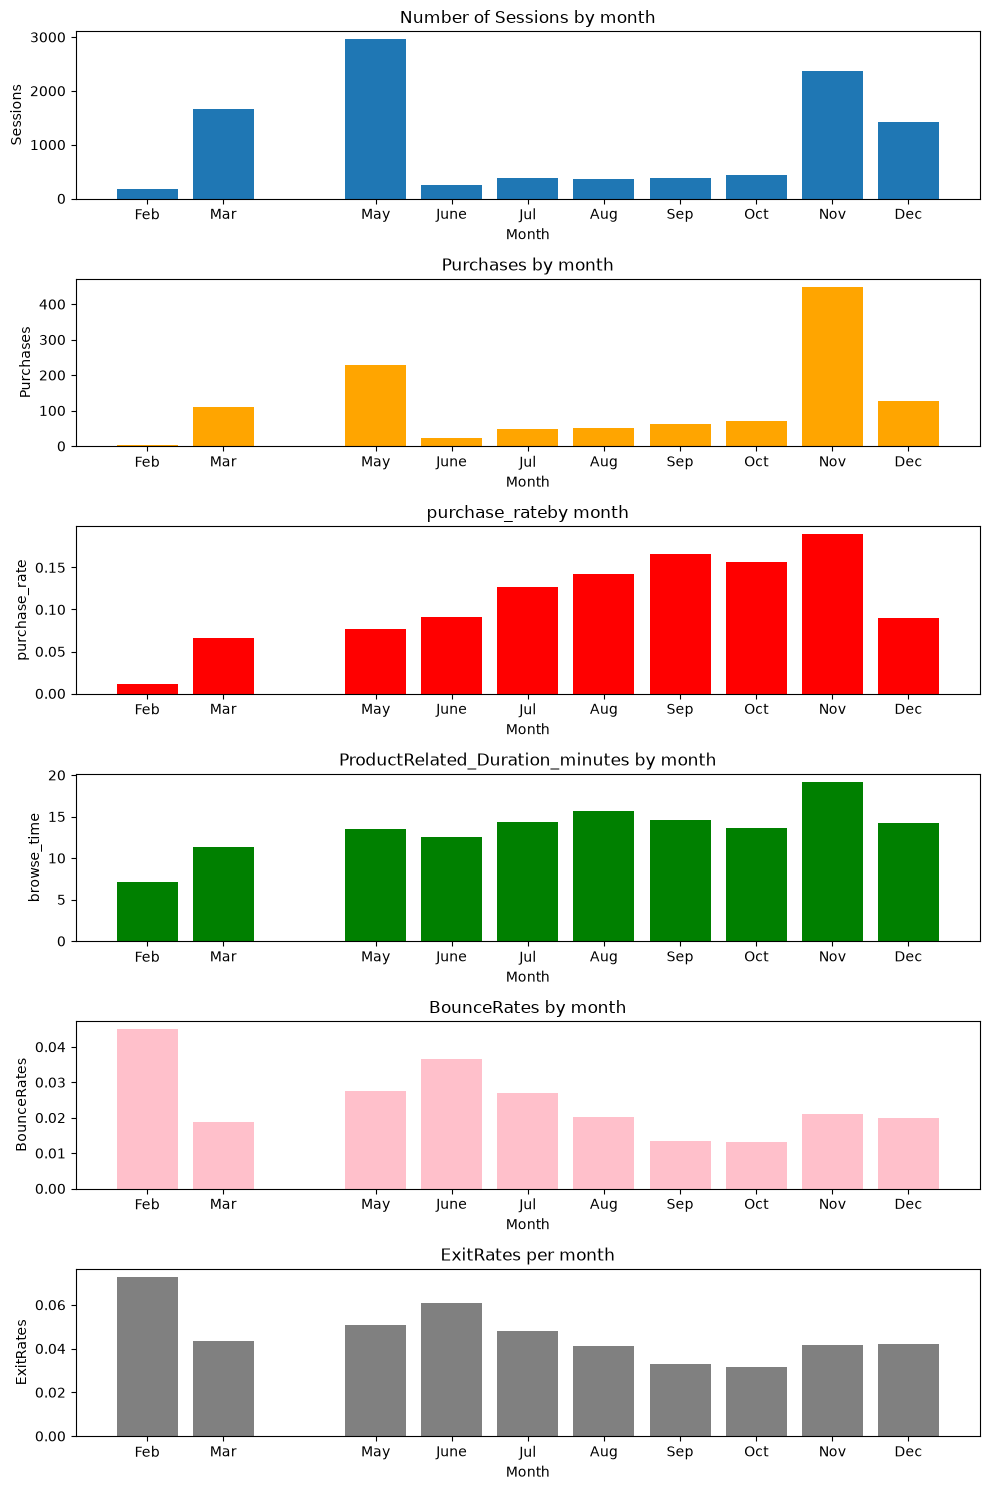

In [28]:
fig, (ax1, ax2, ax3, ax4, ax5, ax6) = plt.subplots(6, 1, figsize=(10, 15), sharex=True)

ax1.bar(lucrative_period_deep['Month_n'], lucrative_period_deep['sessions'])
ax1.set_ylabel('Sessions')
ax1.set_title('Number of Sessions by month')

ax2.bar(lucrative_period_deep['Month_n'], lucrative_period_deep['purchases'], color='orange')
ax2.set_ylabel('Purchases')
ax2.set_title('Purchases by month')

ax3.bar(lucrative_period_deep['Month_n'], lucrative_period_deep['purchase_rate'], color='red')
ax3.set_ylabel('purchase_rate')
ax3.set_title('purchase_rateby month')

ax4.bar(lucrative_period_deep['Month_n'], lucrative_period_deep['browse_time'], color='green')
ax4.set_ylabel('browse_time')
ax4.set_title('ProductRelated_Duration_minutes by month')

ax5.bar(lucrative_period_deep['Month_n'], lucrative_period_deep['avg_bounce_rate'], color='pink')
ax5.set_ylabel('BounceRates')
ax5.set_title('BounceRates by month')

ax6.bar(lucrative_period_deep['Month_n'], lucrative_period_deep['avg_exit_rates'], color='grey')
ax6.set_ylabel('ExitRates')
ax6.set_title('ExitRates per month')

for ax in (ax1, ax2, ax3, ax4, ax5, ax6):
    ax.set_xticks(lucrative_period_deep['Month_n'])                          # a tick at every month
    ax.set_xticklabels(lucrative_period_deep['Month'])                        # name each tick
    ax.tick_params(labelbottom=True)     # show labels even on shared axes
    ax.set_xlabel('Month')

plt.tight_layout()
plt.show()

In [29]:
## Aggregate based on revenue - organize by VisitorType?
Visitor_type = final_df.groupby('VisitorType')['converted_revenue'].agg(sessions="count", purchases="sum", purchase_per_sessions = "mean").sort_values("purchase_per_sessions", ascending=False)
Visitor_type


,sessions,purchases,purchase_per_sessions
VisitorType,,,
New_Visitor,1445,248,0.171626
Returning_Visitor,8953,923,0.103094


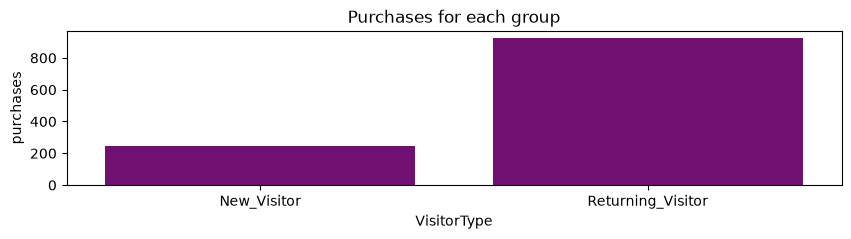

In [30]:
plt.figure(figsize = (10,2))
sns.barplot(x='VisitorType', y='purchases', data=Visitor_type, color='purple')
plt.title('Purchases for each group')
plt.show()

In [31]:
## How do new and returning visitors differ in purchase rate and browsing behavior?

new_return = (final_df.groupby('VisitorType')[['converted_revenue', 'ProductRelated_Duration_minutes', 'BounceRates', 'ExitRates']]
       .agg(sessions=('converted_revenue', 'count'),
            purchases=('converted_revenue', 'sum'),
            purchase_rate=('converted_revenue', 'mean'),
            browse_time=('ProductRelated_Duration_minutes', 'mean'),
            avg_bounce_rate=('BounceRates', 'mean'),
            avg_exit_rates=('ExitRates', 'mean')).reset_index()
)
       
new_return


,VisitorType,sessions,purchases,purchase_rate,browse_time,avg_bounce_rate,avg_exit_rates
0,New_Visitor,1445,248,0.171626,9.481692,0.005872,0.022217
1,Returning_Visitor,8953,923,0.103094,15.407656,0.025414,0.048722


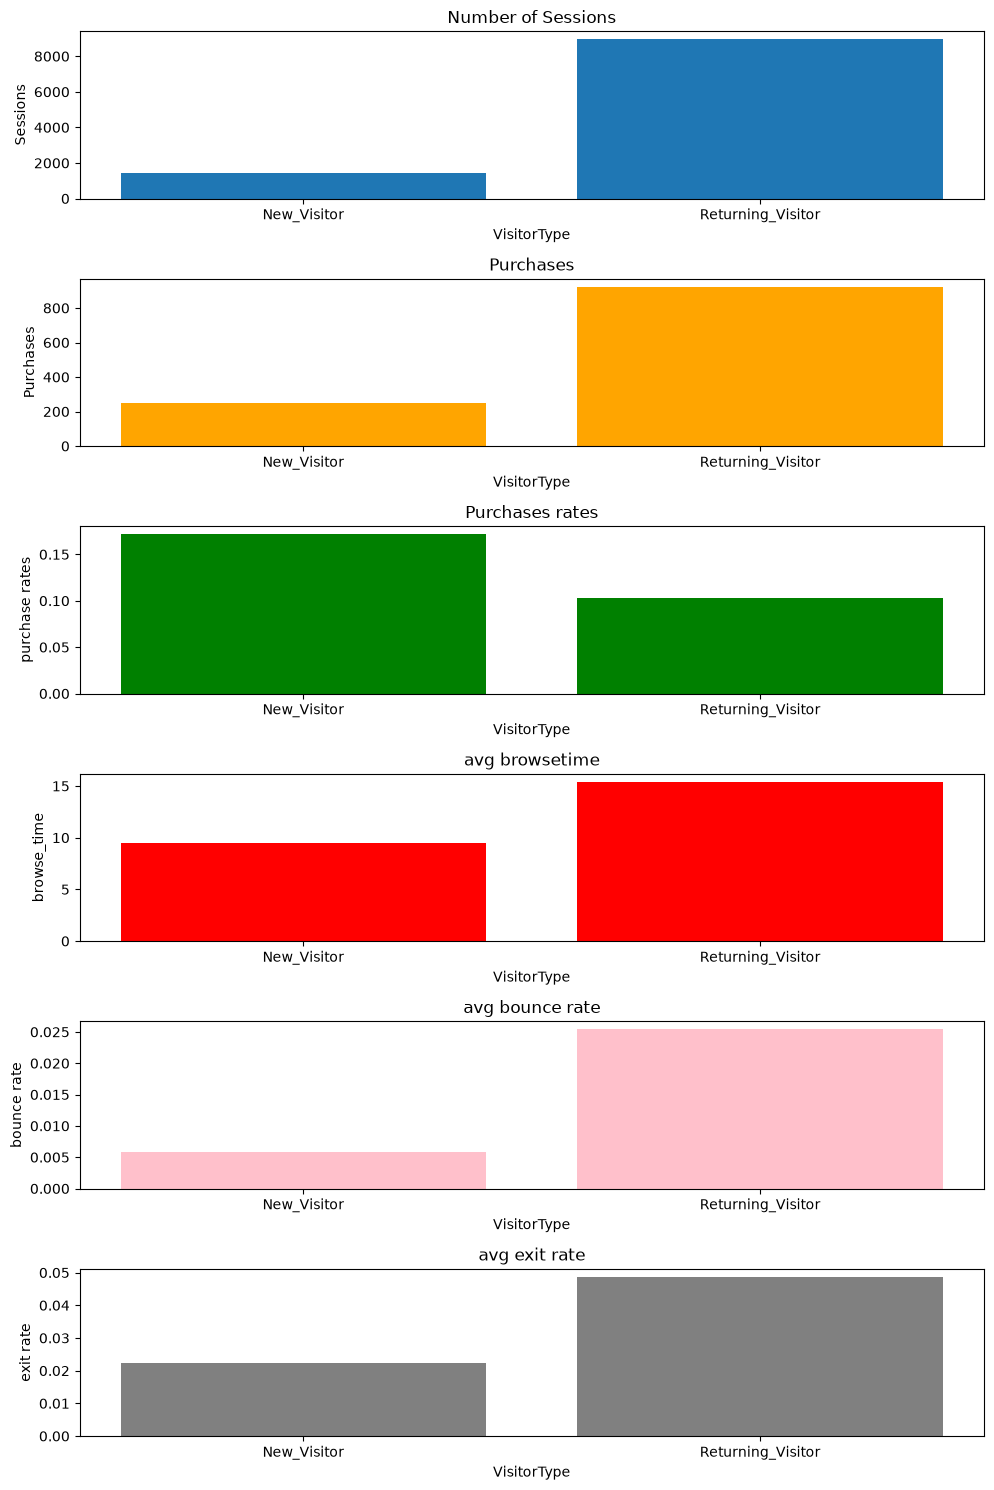

In [32]:
fig, (ax1, ax2, ax3, ax4, ax5, ax6) = plt.subplots(6, 1, figsize=(10, 15), sharex=True)

ax1.bar(new_return['VisitorType'], new_return['sessions'])
ax1.set_ylabel('Sessions')
ax1.set_title('Number of Sessions')

ax2.bar(new_return['VisitorType'], new_return['purchases'], color='orange')
ax2.set_ylabel('Purchases')
ax2.set_title('Purchases')

ax3.bar(new_return['VisitorType'], new_return['purchase_rate'], color='green')
ax3.set_ylabel('purchase rates')
ax3.set_title('Purchases rates')

ax4.bar(new_return['VisitorType'], new_return['browse_time'], color='red')
ax4.set_ylabel('browse_time')
ax4.set_title('avg browsetime')

ax5.bar(new_return['VisitorType'], new_return['avg_bounce_rate'], color='pink')
ax5.set_ylabel('bounce rate')
ax5.set_title('avg bounce rate')

ax6.bar(new_return['VisitorType'], new_return['avg_exit_rates'], color='grey')
ax6.set_ylabel('exit rate')
ax6.set_title('avg exit rate')

for ax in (ax1, ax2, ax3, ax4, ax5, ax6):
    ax.set_xticks(new_return['VisitorType'])                          # a tick at every month
    ax.set_xticklabels(new_return['VisitorType'])                        # name each tick
    ax.tick_params(labelbottom=True)     # show labels even on shared axes
    ax.set_xlabel('VisitorType')

plt.tight_layout()
plt.show()

In [ ]:
# more variables need to be tested:
#  special day, weekend, pagevalues

# Regression related question


### Are people who spend more time browsing products more likely to purchase?


In [34]:
#Are people who spend more time browsing products more likely to purchase?

corr = final_df[['converted_revenue', 'BounceRates']].corr()
corr

# this is quite weak correlation. close to 0. also the direction is negatvie. higher bounce rate little less likely to end in a purchase.

,converted_revenue,BounceRates
converted_revenue,1.000000,-0.122956
BounceRates,-0.122956,1.000000


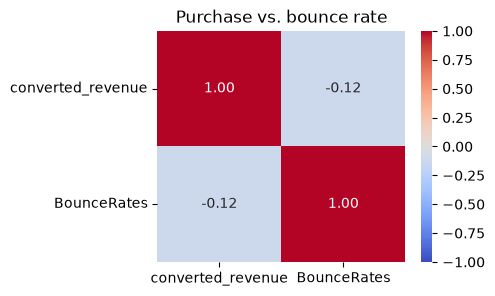

In [35]:
plt.figure(figsize=(4, 3))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Purchase vs. bounce rate')
plt.show()

In [36]:
import statsmodels.formula.api as smf
m = smf.ols('converted_revenue ~ BounceRates', data=final_df).fit(cov_type='HC1')
print(m.summary())

# Null hypothesis: the increase in bounce rates has no effect on our result, h1: bounce rate has effect on our result.
# p value shows we reject the null.  
# our base is 13%.
# R squared: explains the variances of depdent variable that can be explained by independent variabl'es variance.  so in this case, about 1.5% of the variation in purhcase can be explained by the bounce rate. 
# F stat only useful when multiple varriables
# 

                            OLS Regression Results                            
Dep. Variable:      converted_revenue   R-squared:                       0.015
Model:                            OLS   Adj. R-squared:                  0.015
Method:                 Least Squares   F-statistic:                     699.8
Date:                Mon, 09 Nov 2026   Prob (F-statistic):          2.67e-149
Time:                        13:33:35   Log-Likelihood:                -2700.4
No. Observations:               10398   AIC:                             5405.
Df Residuals:                   10396   BIC:                             5419.
Df Model:                           1                                         
Covariance Type:                  HC1                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       0.1310      0.004     36.447      

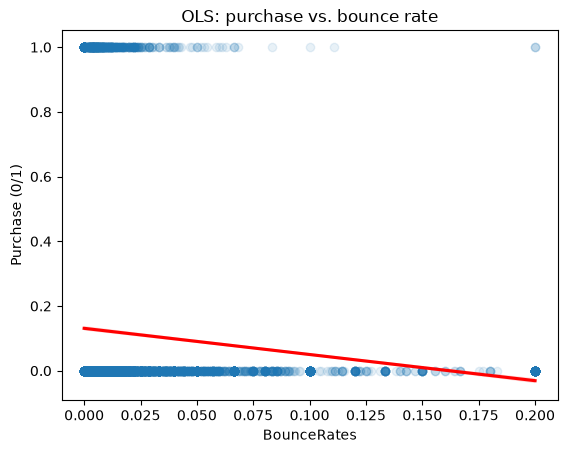

In [37]:
sns.regplot(x='BounceRates', y='converted_revenue', data=final_df,
            scatter_kws={'alpha': 0.1}, line_kws={'color': 'red'})
plt.title('OLS: purchase vs. bounce rate')
plt.ylabel('Purchase (0/1)')
plt.show()

In [44]:
logit = smf.logit('converted_revenue ~ BounceRates', data=final_df).fit()
print(logit.summary())

print(logit.get_margeff().summary())   # effects in probability terms


Optimization terminated successfully.
         Current function value: 0.338340
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:      converted_revenue   No. Observations:                10398
Model:                          Logit   Df Residuals:                    10396
Method:                           MLE   Df Model:                            1
Date:                Mon, 09 Nov 2026   Pseudo R-squ.:                 0.03868
Time:                        13:36:57   Log-Likelihood:                -3518.1
converged:                       True   LL-Null:                       -3659.6
Covariance Type:            nonrobust   LLR p-value:                 1.569e-63
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -1.7792      0.035    -51.071      0.000      -1.848      -1.711
BounceRates   -25.1464    

In [ ]:
# Logit: bounce rate is negatively and significantly associated with purchase (p < 0.001).
# Average marginal effect: +0.01 in bounce rate -> about 2.5 pp lower purchase probability,
# about 3x the OLS estimate (0.8 pp), because the effect is steepest near zero bounce rate.
# Pseudo R² = 0.039: bounce rate alone explains little; more predictors are needed.


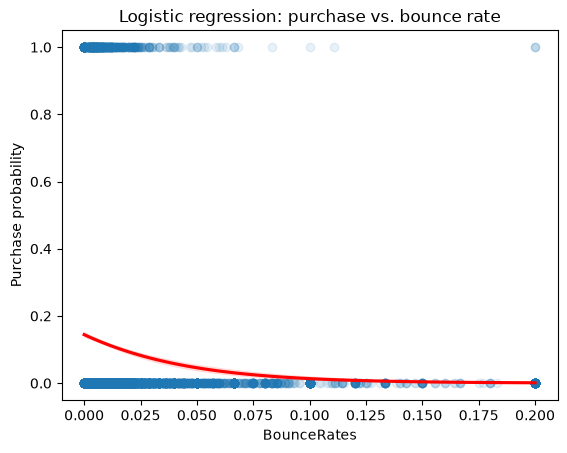

In [45]:
sns.regplot(x='BounceRates', y='converted_revenue', data=final_df, logistic=True,
            scatter_kws={'alpha': 0.1}, line_kws={'color': 'red'})
plt.title('Logistic regression: purchase vs. bounce rate')
plt.ylabel('Purchase probability')
plt.show()

## Testing more variables

In [54]:
formula = ('converted_revenue ~ BounceRates + np.log1p(ProductRelated_Duration_minutes)'
           ' + PageValues + C(VisitorType) + Weekend + C(Month) + SpecialDay')
ols_full = smf.ols(formula, data=final_df).fit(cov_type='HC1')
ols_full.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      converted_revenue   R-squared:                       0.329
Model:                            OLS   Adj. R-squared:                  0.328
Method:                 Least Squares   F-statistic:                     133.2
Date:                Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:33:42   Log-Likelihood:                -707.18
No. Observations:               10398   AIC:                             1446.
Df Residuals:                   10382   BIC:                             1562.
Df Model:                          15                                         
Covariance Type:                  HC1                                         
=============================================================================================================
                                                coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------
Intercept                                     0.0820      0.018      4.473      0.000       0.046       0.118
C(VisitorType)[T.Returning_Visitor]          -0.0467      0.008     -5.701      0.000      -0.063      -0.031
Weekend[T.True]                               0.0131      0.006      2.098      0.036       0.001       0.025
C(Month)[T.Dec]                              -0.0393      0.017     -2.310      0.021      -0.073      -0.006
C(Month)[T.Feb]                              -0.0531      0.018     -3.034      0.002      -0.087      -0.019
C(Month)[T.Jul]                              -0.0025      0.022     -0.113      0.910      -0.045       0.040
C(Month)[T.June]                             -0.0275      0.021     -1.303      0.193      -0.069       0.014
C(Month)[T.Mar]                              -0.0418      0.016     -2.536      0.011      -0.074      -0.009
C(Month)[T.May]                              -0.0481      0.016     -2.933      0.003      -0.080      -0.016
C(Month)[T.Nov]                               0.0471      0.017      2.725      0.006       0.013       0.081
C(Month)[T.Oct]                              -0.0056      0.021     -0.263      0.792      -0.047       0.036
C(Month)[T.Sep]                               0.0127      0.024      0.538      0.591      -0.033       0.059
BounceRates                                  -0.1384      0.035     -3.932      0.000      -0.207      -0.069
np.log1p(ProductRelated_Duration_minutes)     0.0136      0.003      5.152      0.000       0.008       0.019
PageValues                                    0.0222      0.001     35.852      0.000       0.021       0.023
SpecialDay                                    0.0018      0.009      0.197      0.844      -0.016       0.020
==============================================================================
Omnibus:                     3722.580   Durbin-Watson:                   2.028
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            18299.436
Skew:                           1.669   Prob(JB):                         0.00
Kurtosis:                       8.577   Cond. No.                         197.
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC1)
"""

In [51]:
final_df.PageValues.mean()

np.float64(2.6041183403750723)

In [ ]:
#PageValues comes from Google Analytics. It is the average "page value" of the pages a visitor viewed in that session.

#Google Analytics gives each page a value based on how often it appears on the way to a purchase:

# ▎ Page value = (revenue from sessions that viewed this page before buying) ÷ (unique views of that page)

In [55]:
formula = ('converted_revenue ~ BounceRates + np.log1p(ProductRelated_Duration_minutes)'
           ' + PageValues + C(VisitorType) + Weekend + C(Month) + SpecialDay')
logit_full = smf.logit(formula, data=final_df).fit()
print(logit_full.get_margeff().summary())

Optimization terminated successfully.
         Current function value: 0.236278
         Iterations 9
        Logit Marginal Effects       
Dep. Variable:      converted_revenue
Method:                          dydx
At:                           overall
                                               dy/dx    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------
C(VisitorType)[T.Returning_Visitor]          -0.0358      0.007     -5.278      0.000      -0.049      -0.022
Weekend[T.True]                               0.0120      0.006      2.099      0.036       0.001       0.023
C(Month)[T.Dec]                              -0.0429      0.014     -3.009      0.003      -0.071      -0.015
C(Month)[T.Feb]                              -0.1479      0.055     -2.673      0.008      -0.256      -0.039
C(Month)[T.Jul]                              -0.0006      0.017     -0.034      0.973 

In [56]:
base = ('converted_revenue ~ BounceRates + np.log1p(ProductRelated_Duration_minutes)'
        ' + C(VisitorType) + Weekend + C(Month) + SpecialDay')
logit_no_pv = smf.logit(base, data=final_df).fit(disp=0)
logit_pv    = smf.logit(base + ' + PageValues', data=final_df).fit(disp=0)

print('Pseudo R2 without PageValues:', round(logit_no_pv.prsquared, 3))
print('Pseudo R2 with PageValues:   ', round(logit_pv.prsquared, 3))
logit_no_pv.get_margeff().summary()

Pseudo R2 without PageValues: 0.104
Pseudo R2 with PageValues:    0.329


<class 'statsmodels.iolib.summary.Summary'>
"""
        Logit Marginal Effects       
=====================================
Dep. Variable:      converted_revenue
Method:                          dydx
At:                           overall
=============================================================================================================
                                               dy/dx    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------
C(VisitorType)[T.Returning_Visitor]          -0.0496      0.008     -6.244      0.000      -0.065      -0.034
Weekend[T.True]                               0.0062      0.007      0.893      0.372      -0.007       0.020
C(Month)[T.Dec]                              -0.0525      0.017     -3.135      0.002      -0.085      -0.020
C(Month)[T.Feb]                              -0.1938      0.068     -2.851      0.004      -0.327      -0.061
C(Month)[T.Jul]                           -7.292e-05      0.020     -0.004      0.997      -0.040       0.040
C(Month)[T.June]                             -0.0258      0.025     -1.021      0.307      -0.075       0.024
C(Month)[T.Mar]                              -0.0727      0.017     -4.269      0.000      -0.106      -0.039
C(Month)[T.May]                              -0.0413      0.016     -2.574      0.010      -0.073      -0.010
C(Month)[T.Nov]                               0.0234      0.015      1.550      0.121      -0.006       0.053
C(Month)[T.Oct]                               0.0087      0.019      0.459      0.646      -0.028       0.046
C(Month)[T.Sep]                               0.0121      0.019      0.626      0.531      -0.026       0.050
BounceRates                                  -1.9864      0.259     -7.658      0.000      -2.495      -1.478
np.log1p(ProductRelated_Duration_minutes)     0.0436      0.003     13.938      0.000       0.037       0.050
SpecialDay                                   -0.0699      0.023     -2.985      0.003      -0.116      -0.024
=============================================================================================================
"""

In [59]:
# Model A excludes PageValues (built from purchases, so a leakage risk); Model B includes it.
# The jump in pseudo R² shows how much PageValues alone explains.
# I interpret behavior effects from Model A.